Group Project Code: Data Mining ITCS 3162

By: Caroline Deese, Elena Arroyo, Vivien Li, Harrison Syfert, and Dakoda Fisher

**Phase 1: Setup and Data Loading**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

**Caroline** - Project Manager

**Elena** - Editorial Lead

**Vivien** - Editorial Assistant

**Dakoda** - Visual Design Lead

**Harrison** - Visual Design Assistant

**Central Question:** Which combination of property attributes determines whether a property is significantly over/under-priced relative to its zip code median price-per-square-foot? Which attribute has the highest impact? Which attribute has the lowest impact?

**Loading the dataset:** Click on this link https://www.kaggle.com/datasets/ahmedshahriarsakib/usa-real-estate-dataset/data , download the zip file, extract the csv from the zip file, make sure that the end of the csv says 'realtor-data.csv' and not 'realtor-data.zip.csv' (change the name of the file if need be), and have the csv in the same folder as this notebook file.



In [2]:
realty = pd.read_csv("realtor-data.csv")
print(realty.describe())
print(realty.info())
print(realty.head(10))

        brokered_by         price           bed          bath      acre_lot  \
count  2.221849e+06  2.224841e+06  1.745065e+06  1.714611e+06  1.900793e+06   
mean   5.293989e+04  5.241955e+05  3.275841e+00  2.496440e+00  1.522303e+01   
std    3.064275e+04  2.138893e+06  1.567274e+00  1.652573e+00  7.628238e+02   
min    0.000000e+00  0.000000e+00  1.000000e+00  1.000000e+00  0.000000e+00   
25%    2.386100e+04  1.650000e+05  3.000000e+00  2.000000e+00  1.500000e-01   
50%    5.288400e+04  3.250000e+05  3.000000e+00  2.000000e+00  2.600000e-01   
75%    7.918300e+04  5.500000e+05  4.000000e+00  3.000000e+00  9.800000e-01   
max    1.101420e+05  2.147484e+09  4.730000e+02  8.300000e+02  1.000000e+05   

             street      zip_code    house_size  
count  2.215516e+06  2.226083e+06  1.657898e+06  
mean   1.012325e+06  5.218668e+04  2.714471e+03  
std    5.837635e+05  2.895408e+04  8.081635e+05  
min    0.000000e+00  0.000000e+00  4.000000e+00  
25%    5.063128e+05  2.961700e+04  1.3

**Phase 2: Exploratory Data Analysis**

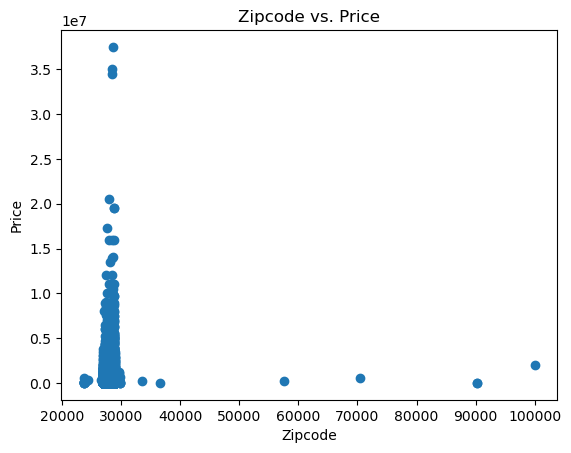

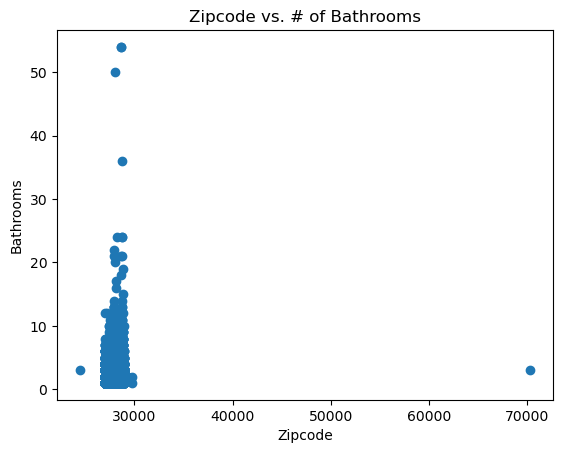

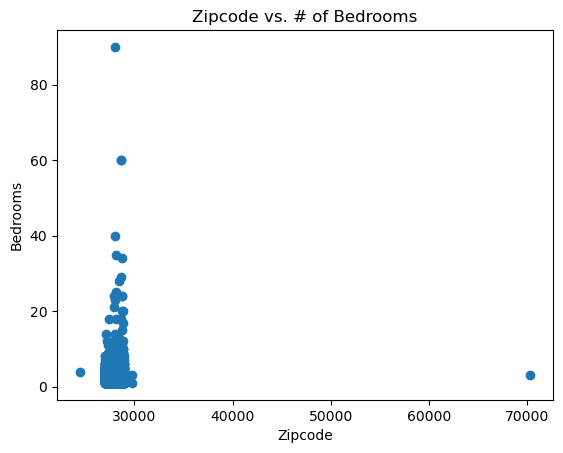

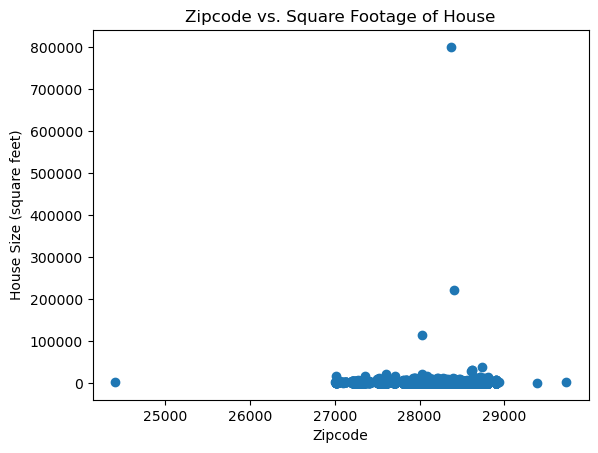

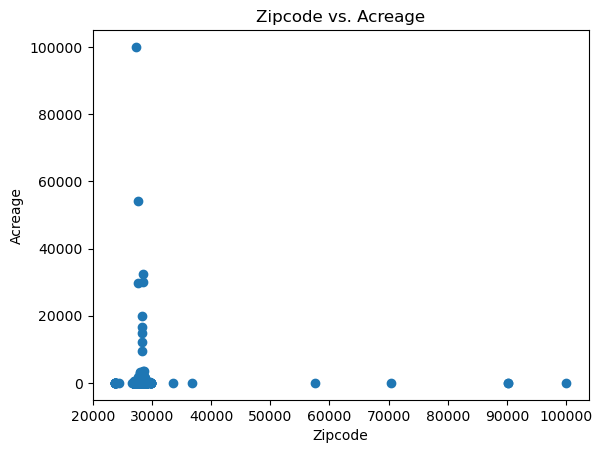

In [3]:
realty2 = realty[realty['state']=='North Carolina']
realty2.to_csv("NCListings.csv",index = False)
realty3 = pd.read_csv("NCListings.csv")


plt.scatter(realty3['zip_code'],realty3['price'])
plt.xlabel("Zipcode")
plt.ylabel("Price")
plt.title("Zipcode vs. Price")
plt.show()

plt.scatter(realty3['zip_code'],realty3['bath'])
plt.xlabel("Zipcode")
plt.ylabel("Bathrooms")
plt.title("Zipcode vs. # of Bathrooms")
plt.show()

plt.scatter(realty3['zip_code'],realty3['bed'])
plt.xlabel('Zipcode')
plt.ylabel("Bedrooms")
plt.title("Zipcode vs. # of Bedrooms")
plt.show()

plt.scatter(realty3['zip_code'],realty3['house_size'])
plt.xlabel('Zipcode')
plt.ylabel('House Size (square feet)')
plt.title("Zipcode vs. Square Footage of House")
plt.show()

plt.scatter(realty3['zip_code'],realty3['acre_lot'])
plt.xlabel('Zipcode')
plt.ylabel('Acreage')
plt.title("Zipcode vs. Acreage")
plt.show()

**Exploratory Data Analysis:** Since our target variable is not in the dataset by default, we will be comparing 'zip_code' to our key variables: bed, bath, house_size, and acre_lot. From what is displayed on the scatterplots, it is obvious that there are some outliers that may skew the results of our models. In order for us to actually get the true medians from the dataset, this may mean that we have to filter the data and obtain the house listings that are in a specific varaible range. 

**Phase 3: Data Cleaning and Preprocessing**


In [4]:
#Extracting the columns/fields that we will be using.
#Removing empty lots with no buildings 
realty4 = realty3[['bed','bath','price','acre_lot','house_size','city','state','zip_code']].dropna()
realty4.to_csv("CleanNCListings.csv",index=False)
df = pd.read_csv("CleanNCListings.csv")

#Adjustment/cleaning of data to remove extreme outliers based on the scatterplots from EDA
df = df[
    (df['price'] > 0) & (df['price'] <= 600000) &
    (df['bath'] <= 10) & (df['bed'] <= 10) &
    (df['house_size'] > 0) & (df['house_size'] <= 50000) &
    (df['acre_lot'] > 0) & (df['acre_lot'] <= 20000)
]


**Data Cleaning and Preprocessing:** In the dataset, there were some listings that were missing values in house_size, bed, and bath. We came to the conclusion that this is because those listings are simply just plots of land with no actual buildings on the lot. Since we are looking at square footage of houses, we chose to filter out the empty plots of land. 

**Phase 4: Modeling**

In [5]:
#Creation of needed variables/fields

df["ppsf"] = df['price'] / df['house_size'] #Price per square footage
df["log_sqft"] = np.log(df["house_size"])
df["log_acre"] = np.log(df["acre_lot"])

features = ['log_sqft','log_acre','bed','bath']
X = df[features]
y = np.log(df["ppsf"])

XTrain, XTest, yTrain, yTest, dfTrain, dfTest = train_test_split(X,y,df,test_size=0.2,random_state=0)
cv = KFold(5, shuffle=True, random_state=0)




In [ ]:
#Baseline Model (for zip-code median)

#Zip Median Model
zip_med = dfTrain.groupby("zip_code")["ppsf"].median() #each zipcode's median PPSF from the training data
dfTest["pred_ppsf"]= dfTest["zip_code"].map(zip_med).fillna(dfTrain["ppsf"].median())
err = np.log(dfTest["pred_ppsf"]) - np.log(dfTest["ppsf"])
print("Zipcode Median log-RMSE: ",round(np.sqrt(np.mean(err**2)),3))
print("Zipcode Median % error: ", round(np.median(np.abs(np.exp(err)-1))*100,1))




Zipcode Median log-RMSE:  0.334
Zipcode median % error:  14.5


*Baseline Model: Zip Median Model*

For our first baseline model, we chose a zipcode median model so that we can first get the median price-per-square-foot for each zipcode. We then gathered the log-RMSE and median percent error so that we can see how far off the model was from the test data.

In [47]:
#Baseline Model (for attributes relative to zip code median)

#Ridge Regression
scaler = StandardScaler()
XTrain_scaled = scaler.fit_transform(XTrain)
XTest_scaled = scaler.transform(XTest)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=cv)
ridge.fit(XTrain_scaled, yTrain)

ridge_preds = ridge.predict(XTest_scaled)
ridge_err = ridge_preds - yTest

print("Best alpha:", round(ridge.alpha_, 4))
print("Ridge log-RMSE:", round(np.sqrt(np.mean(ridge_err ** 2)), 3))
print("Ridge median % error:", round(np.median(np.abs(np.exp(ridge_err) - 1)) * 100, 1))

Best alpha: 25.5955
Ridge log-RMSE: 0.419
Ridge median % error: 21.1


*Baseline Model: Ridge Regression Model*

The second baseline model that we chose was a Ridge regression model. We chose this model for our data, as variables like the house_size, bed, and bath are highly correlated and we wanted the coefficients to be stable. Some hyperparameter tuning was made, as we went through differen alphas in RidgeCV in order to decide which was the best one. It turned out that 25.5955 was the best alpha, making the log-RMSE 0.419 and the median error 21.1%.

In [39]:
#KNN
knn_params = {
    'n_neighbors': [5, 11, 21, 31, 51],
    'weights': ['uniform', 'distance']
}

knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_params,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
knn_grid.fit(XTrain_scaled, yTrain)

best_knn = knn_grid.best_estimator_
knn_preds = best_knn.predict(XTest_scaled)
knn_err = knn_preds - yTest

print("Best KNN params:", knn_grid.best_params_)
print("KNN log-RMSE:", round(np.sqrt(np.mean(knn_err ** 2)), 3))
print("KNN median % error:", round(np.median(np.abs(np.exp(knn_err) - 1)) * 100, 1))


Best KNN params: {'n_neighbors': 51, 'weights': 'distance'}
KNN log-RMSE: 0.4
KNN median % error: 16.3


*MLM 1: KNN Model*

For our first MLM we decided to go with the K-Nearest Neighbors model, as it predicts a property's price-per-square-foot on properties that are similar to it. For the tuning, we decided to do a 5-fold cross-validation and test for the best weights and n_neighbors. The best combination proved to be n_neighbors=51 and weights=distance, with a log-RMSE of 0.4 and median error of 16.3%.

In [40]:

#Decision Tree
dt_params = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 10],
    'min_samples_leaf': [1, 5, 10]
}

dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=0),
    param_grid=dt_params,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Tree models do not require standardized features, so use XTrain and XTest.
dt_grid.fit(XTrain, yTrain)

best_dt = dt_grid.best_estimator_
dt_preds = best_dt.predict(XTest)
dt_err = dt_preds - yTest

print("Best Decision Tree params:", dt_grid.best_params_)
print("Decision Tree log-RMSE:", round(np.sqrt(np.mean(dt_err ** 2)), 3))
print("Decision Tree median % error:",
      round(np.median(np.abs(np.exp(dt_err) - 1)) * 100, 1))


Best Decision Tree params: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2}
Decision Tree log-RMSE: 0.411
Decision Tree median % error: 20.1


*MLM 2: Decision Tree*

For our third MLM we decided to go with a Decision Tree, as it would divide the data up into yes/no rules depending on the fields and would be able to provide us feature importance. When it came to the hyperparameter tuning, we decided to go with a 5-fold cross-validation for max_depth, min_samples_split, and min_samples_leaf. The best hyperparameter combination turned out to be max_depth=10, min_samples_split=2, and min_samples_leaf=10. As far as the performance went, the log-RMSE was 0.411 and the median error being 20.1%.

In [41]:

#Random Forest

rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, None],
    'min_samples_leaf': [1, 5]
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=0, n_jobs=-1),
    param_grid=rf_params,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

rf_grid.fit(XTrain, yTrain)

best_rf = rf_grid.best_estimator_
rf_preds = best_rf.predict(XTest)
rf_err = rf_preds - yTest

print("Best Random Forest params:", rf_grid.best_params_)
print("Random Forest log-RMSE:", round(np.sqrt(np.mean(rf_err ** 2)), 3))
print("Random Forest median % error:",
      round(np.median(np.abs(np.exp(rf_err) - 1)) * 100, 1))


Best Random Forest params: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}
Random Forest log-RMSE: 0.405
Random Forest median % error: 19.7


*MLM 3: Random Forest*

For our final MLM we decided to go with a Random Forest model, as it would be able to model any nonlinearity in the data and provide us with feature importance. For the hyperparameter tuning, we chose to do a GridSearchCV with a 5-fold cross-validation for n_estimators, max_depth, and min_samples_leaf. The best parameters turned out to be n_estimators=100, max_depth=10, and min_samples_leaf = 5. When evaluated on the test set, the log-RMSE was 0.405, and the median error was 19.7%.

In [46]:

# Compare the two models on the same held-out test set.
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Log-RMSE': [
        np.sqrt(np.mean(dt_err ** 2)),
        np.sqrt(np.mean(rf_err ** 2))
    ],
    'Median % Error': [
        np.median(np.abs(np.exp(dt_err) - 1)) * 100,
        np.median(np.abs(np.exp(rf_err) - 1)) * 100
    ]
})

print("\tDecision Tree vs. Random Forest:")
print(model_comparison.round(3).to_string(index=False))


# Feature importance shows which input variables each fitted model used most.
feature_importance = pd.DataFrame({
    'Feature': features,
    'Decision Tree': best_dt.feature_importances_,
    'Random Forest': best_rf.feature_importances_
}).sort_values('Random Forest', ascending=False)

print("\tFeature importance:")
print(feature_importance.round(3).to_string(index=False))


# Written interpretation guide:
# Compare log-RMSE and median percentage error; lower values indicate better
# test-set predictions. Use the feature-importance table to identify which
# property attributes contributed most to each tree-based model.


	Decision Tree vs. Random Forest:
        Model  Log-RMSE  Median % Error
Decision Tree     0.411          20.135
Random Forest     0.405          19.735
	Feature importance:
 Feature  Decision Tree  Random Forest
log_sqft          0.487          0.490
log_acre          0.298          0.315
    bath          0.122          0.105
     bed          0.093          0.090


*Compared Models*

For the comparison models, we decided to go with the Decision Tree and Random Forest models since they are both able to display feature importance. When looking at the feature importance results, it is obvious that the log_sqft has the highest impact on both models. One thing that surprised us was how low the bed field numbers were, as one would think that the number of bedrooms in a house would play a larger role in the price.

**Phase 5: Evaluation and Interpretation**


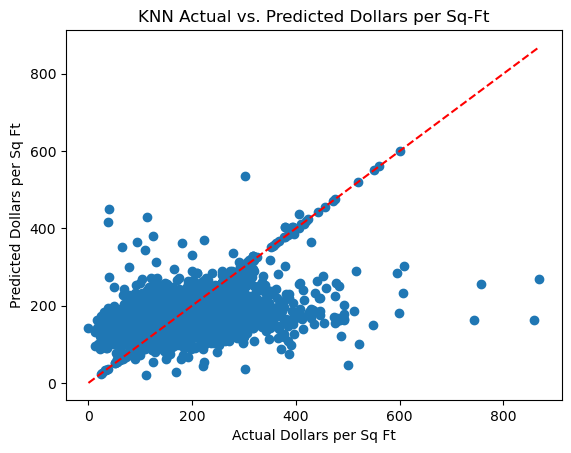

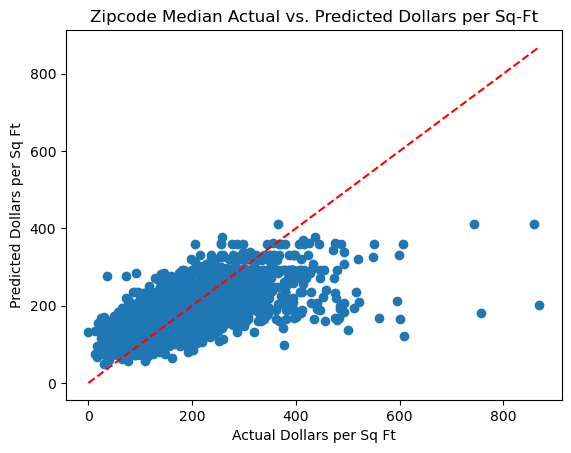

In [50]:
#Actual vs. Predicted dollars per sqft (KNN Model)
actual = np.exp(yTest)
predicted = np.exp(knn_preds)
plt.scatter(actual,predicted)
plt.xlabel("Actual Dollars per Sq Ft")
plt.ylabel("Predicted Dollars per Sq Ft")
plt.title("KNN Actual vs. Predicted Dollars per Sq-Ft")
lim = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
plt.plot(lim, lim, color="red", linestyle="--", label="Perfect prediction")
plt.show()

#Actual vs. Predicted dollars per sqft (Zip median model)
actual2 = dfTest["ppsf"]
predicted2 = dfTest["pred_ppsf"]
plt.scatter(actual2, predicted2)
plt.xlabel("Actual Dollars per Sq Ft")
plt.ylabel("Predicted Dollars per Sq Ft")
plt.title("Zipcode Median Actual vs. Predicted Dollars per Sq-Ft")
lim2 = [min(actual2.min(), predicted2.min()), max(actual2.max(), predicted2.max())]
plt.plot(lim2, lim2 ,color="red", linestyle="--", label="Perfect prediction")
plt.show()

**Reflection:**

By looking at the log-RMSE and median percent error scores of the models that use the attributes relative to its zip code median, you would think that the winning model would be the zipcode medial model. When looking at the two scatter plots above, the winning model turned out to be the KNN model with the scores of 0.4 and 16.3%, as there are more dots on the red line. With the red line on the graph being the perfect prediction, any dot below the red line means that the house sold for more than expected, and any dot above the red line means that the property sold for less than expected.

When talking about the winning model (KNN Model), our model partially answers the question. The KNN model shows that other attributes besides zip-code median (bed,bath,log_sqft,lot_acre) can better predict the price-per-square-foot than the median zip-code ppsf can. The model performs well with prediction, but we wish there was a way for us to see the feature importance like the Decision Tree and Random Forest models. The only part that the model seemed to struggle with by looking at the scatterplot is the listings that had a very high price-per-square-foot. It seems as tho the model predicted the ppsf to be way lower than it actually was. A reason for this error may be that a certain property has a very high ppsf due to other fields that were not included in the dataset, and the houses around it are a lot cheaper. 

If we were to do anything differently, we would most likely go with only models that can give us feature importance so that we can evaluate feature importance across ALL models. 
